In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import simpRepair
import simplification

In [3]:
import sys
import os
sys.path.append(os.path.abspath('../src'))
import matplotlib.pyplot as plt
import numpy as np
import torchvision.transforms.functional as F
from torchvision.models.segmentation import fcn_resnet50
import torch
from torchvision.transforms import GaussianBlur
from torchvision.transforms.v2 import GaussianNoise
import numpy as np
from torchvision.io import read_image
from torchvision.transforms.functional import crop
from torchvision.transforms.functional import convert_image_dtype

from pathlib import Path

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = fcn_resnet50(pretrained=True, progress=False).to(device)
model = model.eval()
for param in model.parameters():
    param.requires_grad_(False)

/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/amikliss/miniforge3/envs/segStrategiesEnv/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FCN_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1`. You can also use `weights=FCN_ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


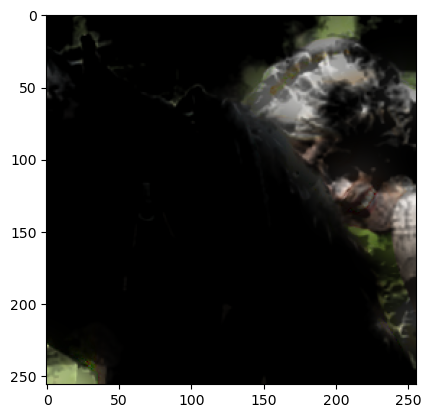

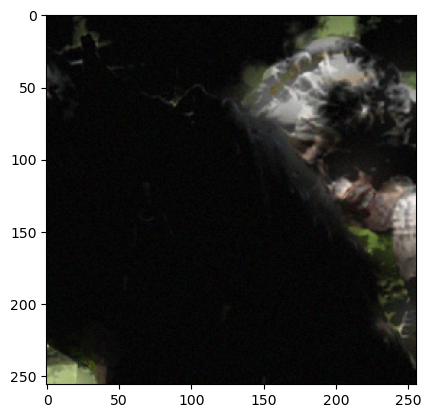

In [14]:
import imageio

# simplification = imageio.v3.imread("Muzzle.tiff")
# simplification = imageio.v3.imread("sheepDrawn.tiff")
simplification = imageio.v3.imread("horsegirl2.tiff")

plt.imshow(simplification)
plt.show()
noise = np.random.rand(
    simplification.shape[0], simplification.shape[1], simplification.shape[2]) * 0.05
noised = simplification + noise
plt.imshow(noised)

# img = read_image(
#     str("/mnt/extraStorage/coco_official_test/test2017/000000501360.jpg"))[:3, :, :]
# img = convert_image_dtype(img, dtype=torch.float).to(device)
# simplification = crop(img, 50, 10, 256, 256).permute(1, 2, 0)

# img = read_image(
#     str(Path('/mnt/extraStorage/example_images_for_coco') / 'testcoco3.png'))[:3, :, :]
# img = convert_image_dtype(img, dtype=torch.float).to(device)
# simplification = crop(img, 60, 30, 280, 280).permute(1, 2, 0)


# img = read_image(
#     str(Path('/mnt/extraStorage/example_images_for_coco') / 'testcoco.png'))[:3, :, :]
# img = convert_image_dtype(img, dtype=torch.float).to(device)
# simplification = crop(img, 10, 50, 256, 256).permute(1, 2, 0)

(256, 256, 3)


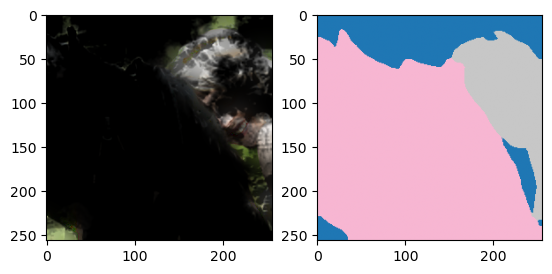

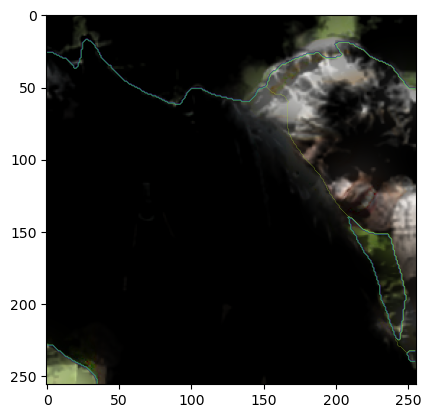

In [15]:
print(simplification.shape)
plt.subplot(1, 2, 1)
plt.imshow(simplification[:, :, :3])
input = torch.tensor(simplification).permute(2, 0, 1).to(
    device="cuda")  # + torch.rand((3, 280, 280)).to(device) * 0.05
input = torch.tensor(simplification[:, :, :3]).permute(2, 0, 1).to(
    device="cuda")  # + torch.rand((3, 280, 280)).to(device) * 0.05
normalized_img = F.normalize(input, mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
output = model(normalized_img.unsqueeze(0))['out']

plt.subplot(1, 2, 2)
plt.imshow(output.argmax(1).cpu().numpy().squeeze(),
           vmin=0, vmax=20, cmap="tab20")
plt.show()

from torchvision.transforms.functional import adjust_contrast

plt.contour(output.argmax(1).cpu().numpy().squeeze(),
            alpha=0.9, linewidths=0.2)
plt.imshow(torch.tensor(
    simplification))
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0166097].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0166097].


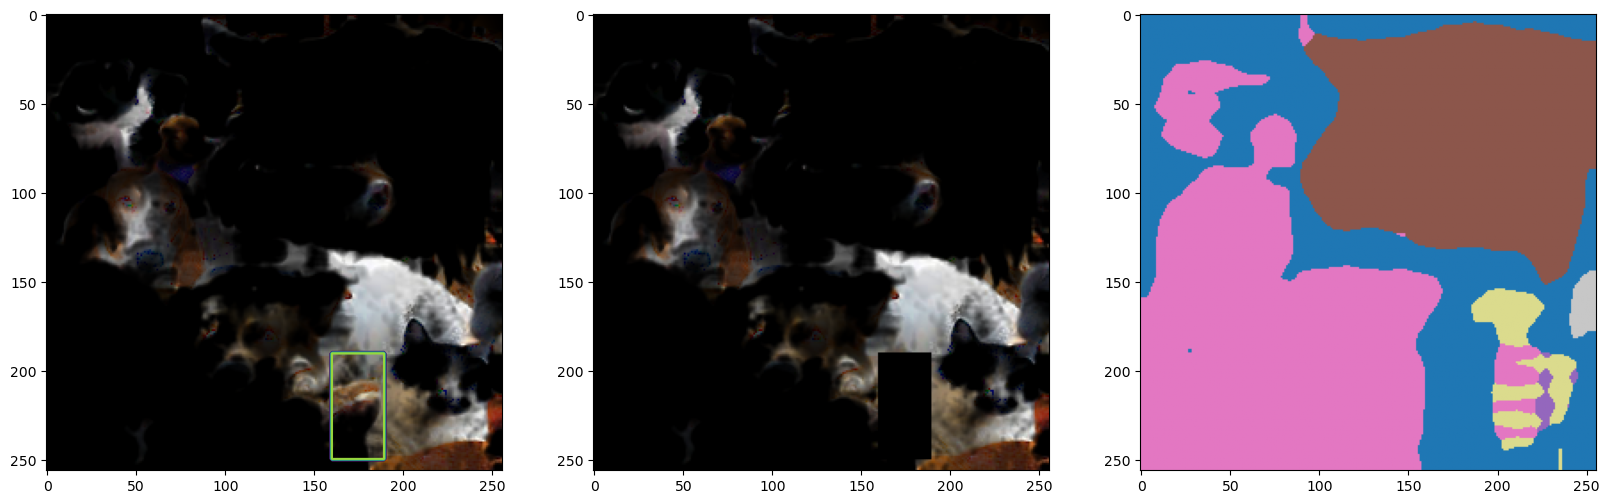

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

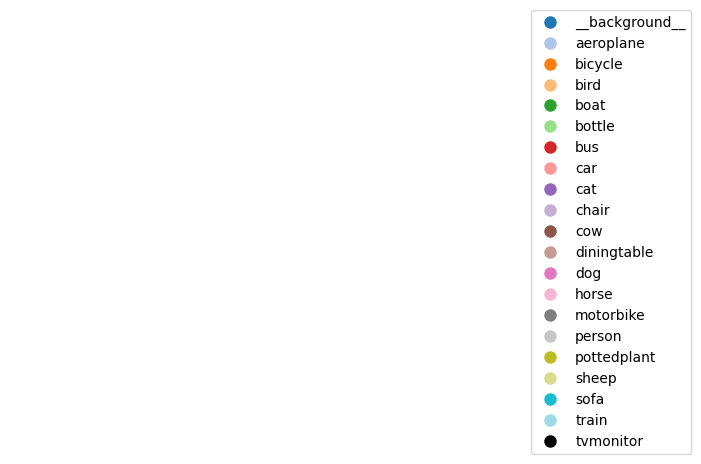

In [9]:
m = torch.zeros_like(torch.tensor(simplification[:, :, 0]))
# m[90:180, 130:190] = 1
# m[80:110, 130:280] = 1
# m[170:190, 130:280] = 1

m[190:250, 160:190] = 1

perturbed = simplification.copy()[:, :, :3]
perturbed[m == 1] = 0

plt.figure(figsize=(20, 40))
plt.subplot(1, 3, 1)
plt.imshow(simplification)
plt.contour(m.squeeze(), alpha=0.9)

plt.subplot(1, 3, 2)
plt.imshow(perturbed)

plt.subplot(1, 3, 3)

torch.tensor(simplification).permute(2, 0, 1).to(
    device="cuda")


input = torch.tensor(perturbed).permute(2, 0, 1).to(
    device="cuda")  # + torch.rand((3, 280, 280)).to(device) * 0.05
normalized_img = F.normalize(input, mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
perturbed_out = model(normalized_img.unsqueeze(0))['out']

plt.imshow(perturbed_out.argmax(1).cpu().numpy().squeeze(),
           cmap="tab20", vmin=0, vmax=20)
plt.show()

from matplotlib.colors import ListedColormap

cmap = ListedColormap(plt.cm.tab20.colors +
                      ((0, 0, 0, 1),))  # RGBA for black
# 21 distinct colors (tab20 + black for the 21st class)
classes = ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus',
           'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike',
           'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']

for cls in classes:
    legend_handles = [plt.Line2D([0], [0], marker='o', color='w', label=cls,
                                 markerfacecolor=cmap(i), markersize=10) for i, cls in enumerate(classes)]
    plt.legend(handles=legend_handles, bbox_to_anchor=(
        1.05, 1), loc='upper left', borderaxespad=0.)
# plt.tight_layout()
plt.axis("off")

RuntimeError: The size of tensor a (4) must match the size of tensor b (3) at non-singleton dimension 0

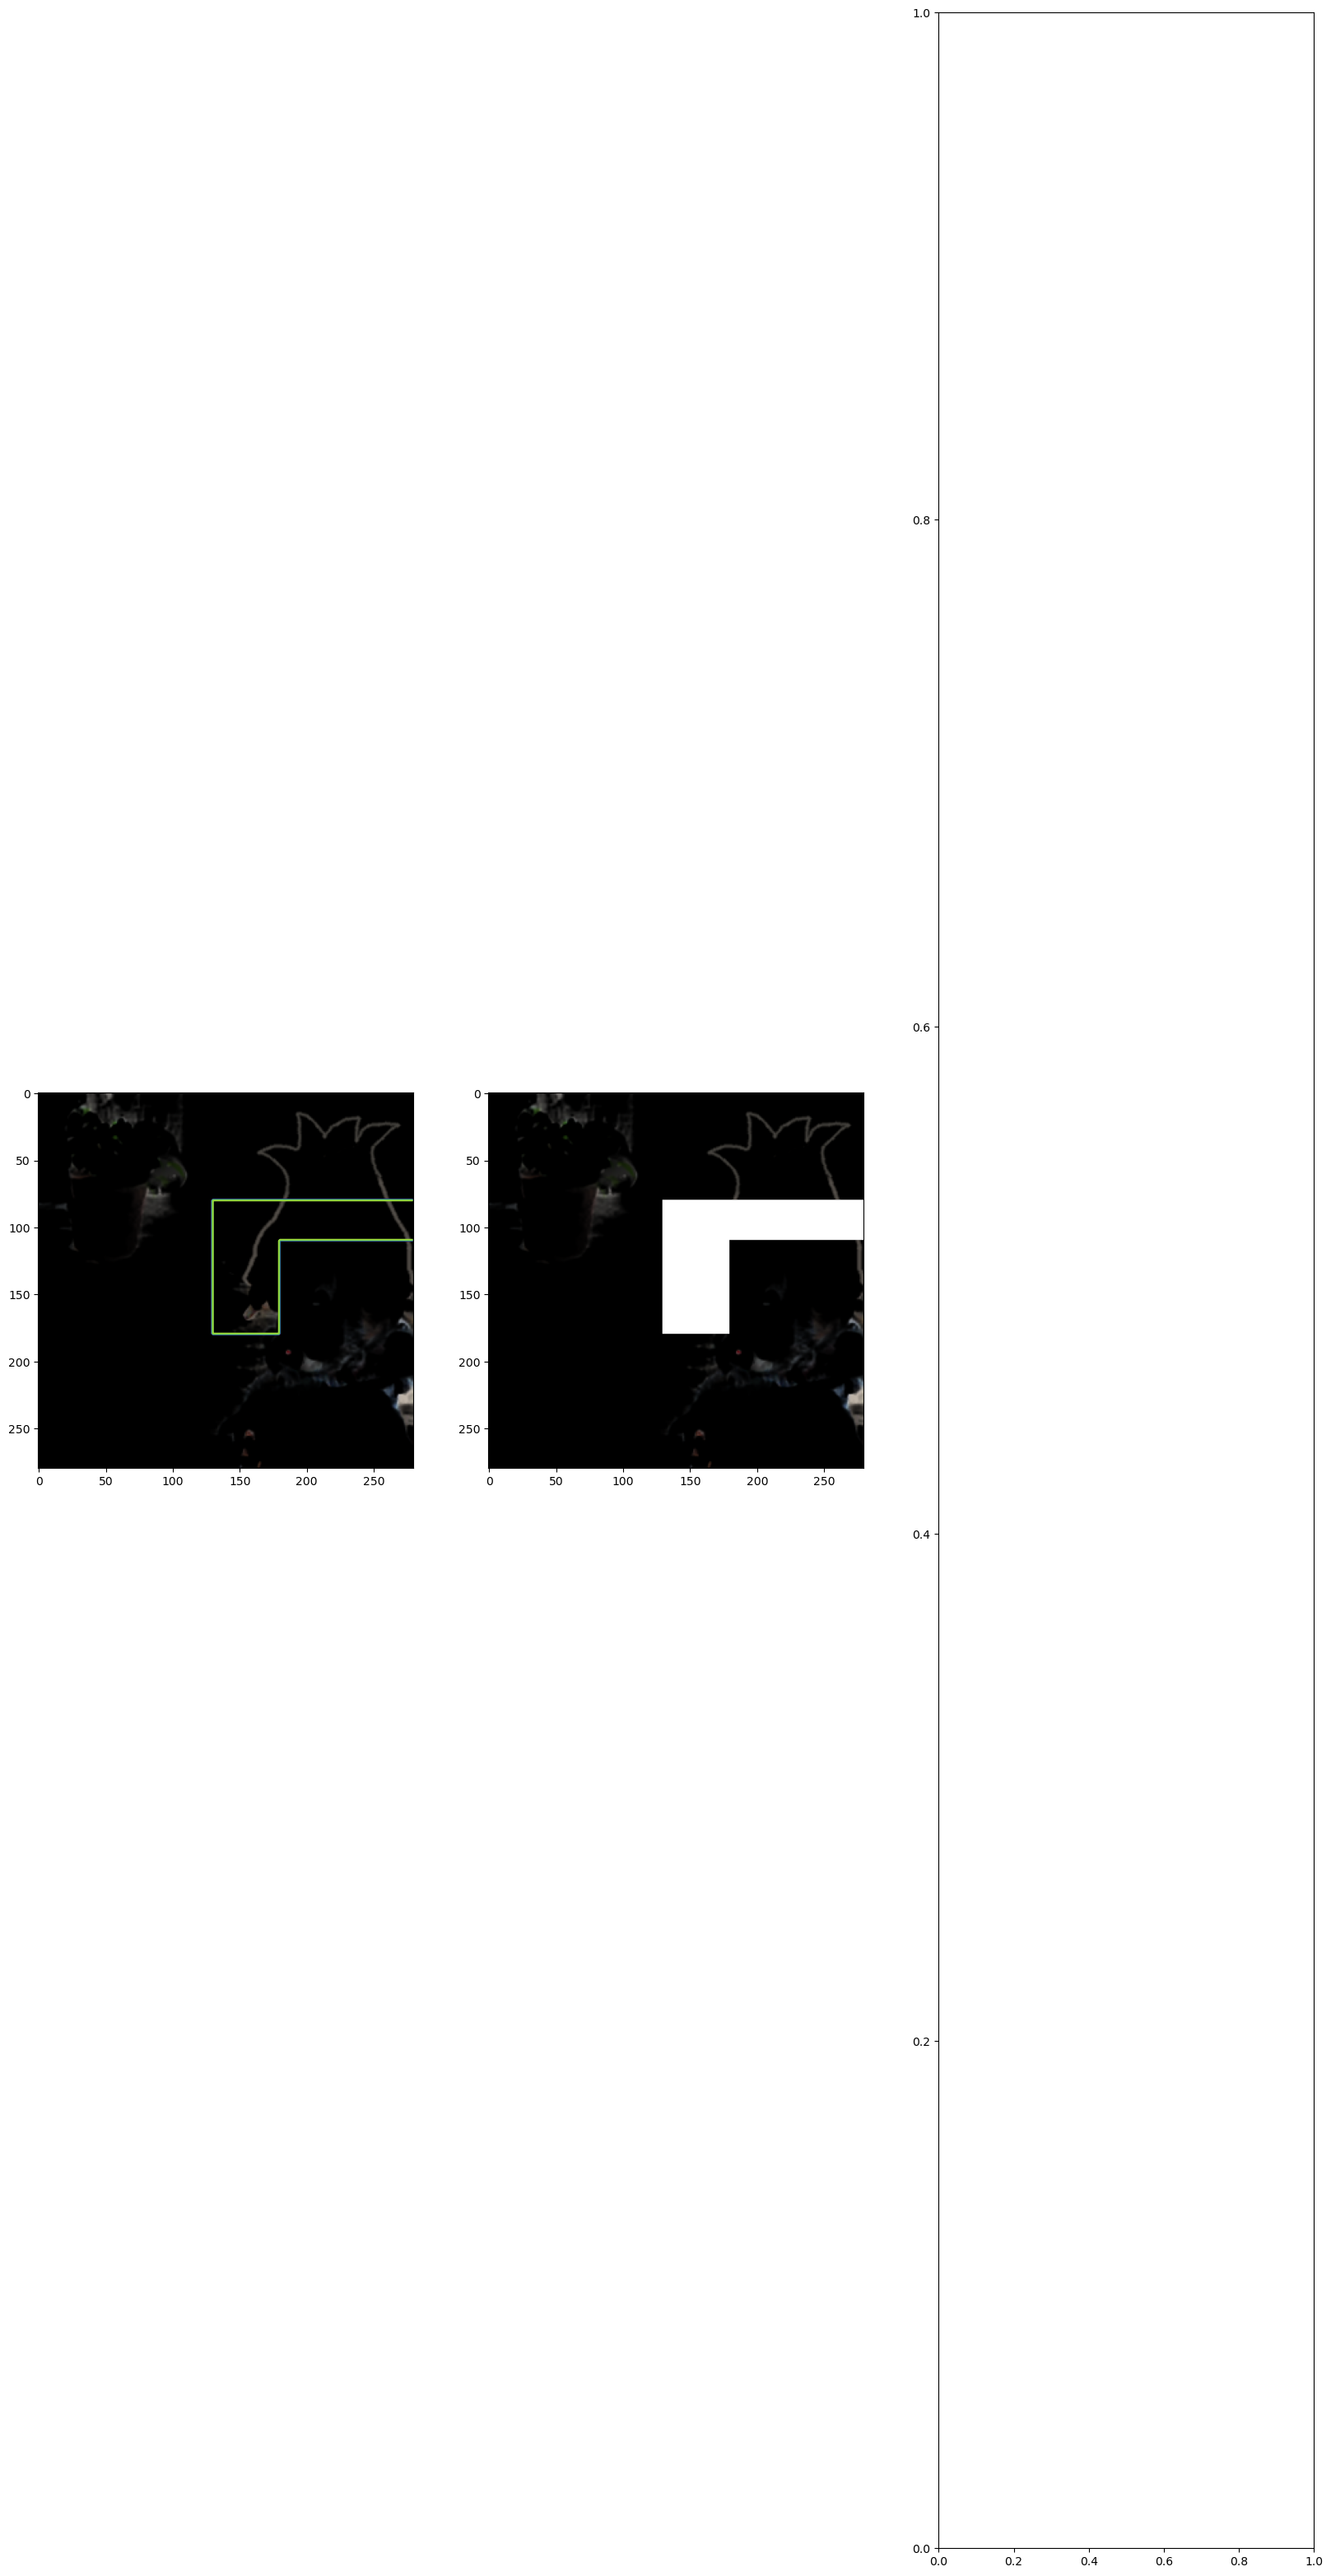

In [180]:
m = torch.zeros_like(torch.tensor(simplification[:, :, 0]))
m[90:180, 130:180] = 1
m[80:110, 130:280] = 1

perturbed = simplification.copy()
perturbed[m == 1] = 0

plt.figure(figsize=(20, 40))
plt.subplot(1, 3, 1)
plt.imshow(simplification)
plt.contour(m.squeeze(), alpha=0.9)

plt.subplot(1, 3, 2)
plt.imshow(perturbed)

plt.subplot(1, 3, 3)

torch.tensor(simplification).permute(2, 0, 1).to(
    device="cuda")


input = torch.tensor(perturbed).permute(2, 0, 1).to(
    device="cuda")  # + torch.rand((3, 280, 280)).to(device) * 0.05
normalized_img = F.normalize(input, mean=(
    0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
perturbed_out = model(normalized_img.unsqueeze(0))['out']

plt.imshow(perturbed_out.argmax(1).cpu().numpy().squeeze())
plt.show()

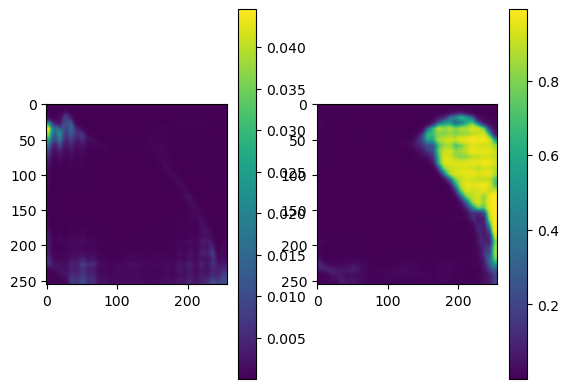

In [58]:
softmax = torch.softmax(output, dim=1)
plt.subplot(1, 2, 1)
plt.imshow(softmax[0, 12].cpu().numpy())
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(softmax[0, 15].cpu().numpy())
plt.colorbar()

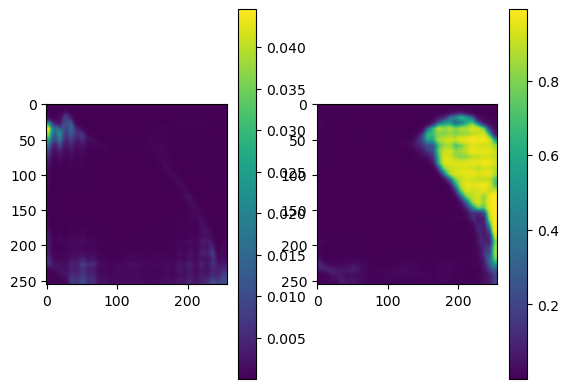

In [59]:
softmax = torch.softmax(output, dim=1)
plt.subplot(1, 2, 1)
plt.imshow(softmax[0, 12].cpu().numpy())
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(softmax[0, 15].cpu().numpy())
plt.colorbar()

In [60]:
print(torch.rand(1))

tensor([0.0026])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0166097].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [1.0550023e-06..1.0577046].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [4.6491624e-07..1.0911767].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [4.4703484e-08..1.1388032].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [2.849102e-06..1.2113739].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [1.0430813e-06..1.2462664].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [8.

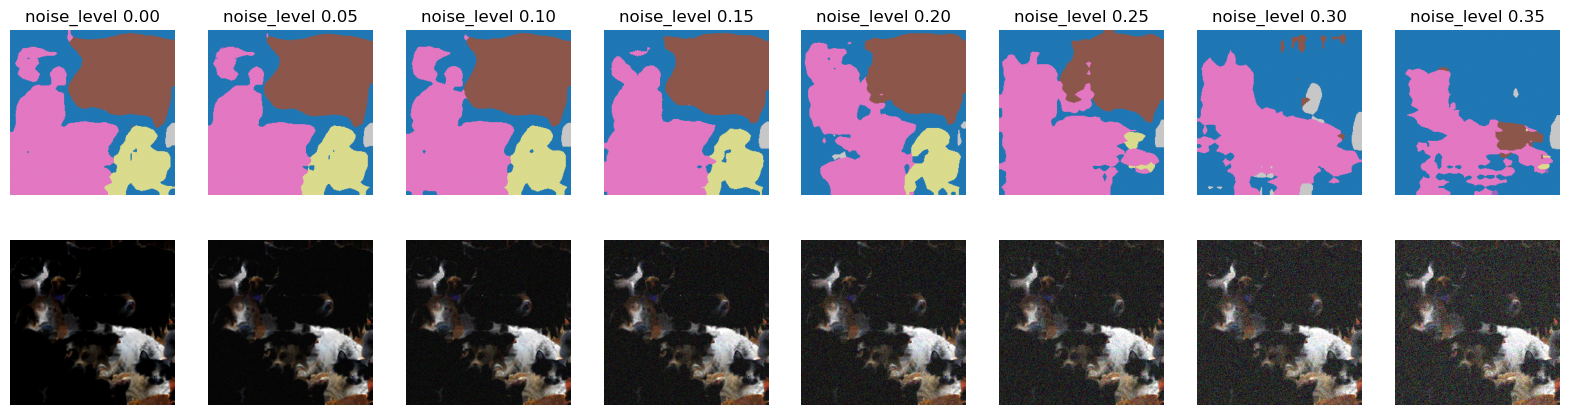

In [10]:
plt.figure(figsize=(20, 5))
noise_level = 0.05
for i in range(8):
    input = torch.tensor(simplification).permute(2, 0, 1).to(device="cuda")
    noise = torch.rand(input.shape) * noise_level * i
    input = input + noise.to(input.device)
    normalized_img = F.normalize(input, mean=(
        0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
    output = model(normalized_img.unsqueeze(0))['out']
    plt.subplot(2, 8, i + 1)
    plt.imshow(output.argmax(1).cpu().numpy().squeeze(),
               vmin=0, vmax=20, cmap="tab20")
    plt.title(f"noise_level {(noise_level * i):.2f}")
    plt.axis("off")
    plt.subplot(2, 8, i + 1 + 8)
    plt.imshow(input.permute(1, 2, 0).cpu().numpy())
    plt.axis("off")

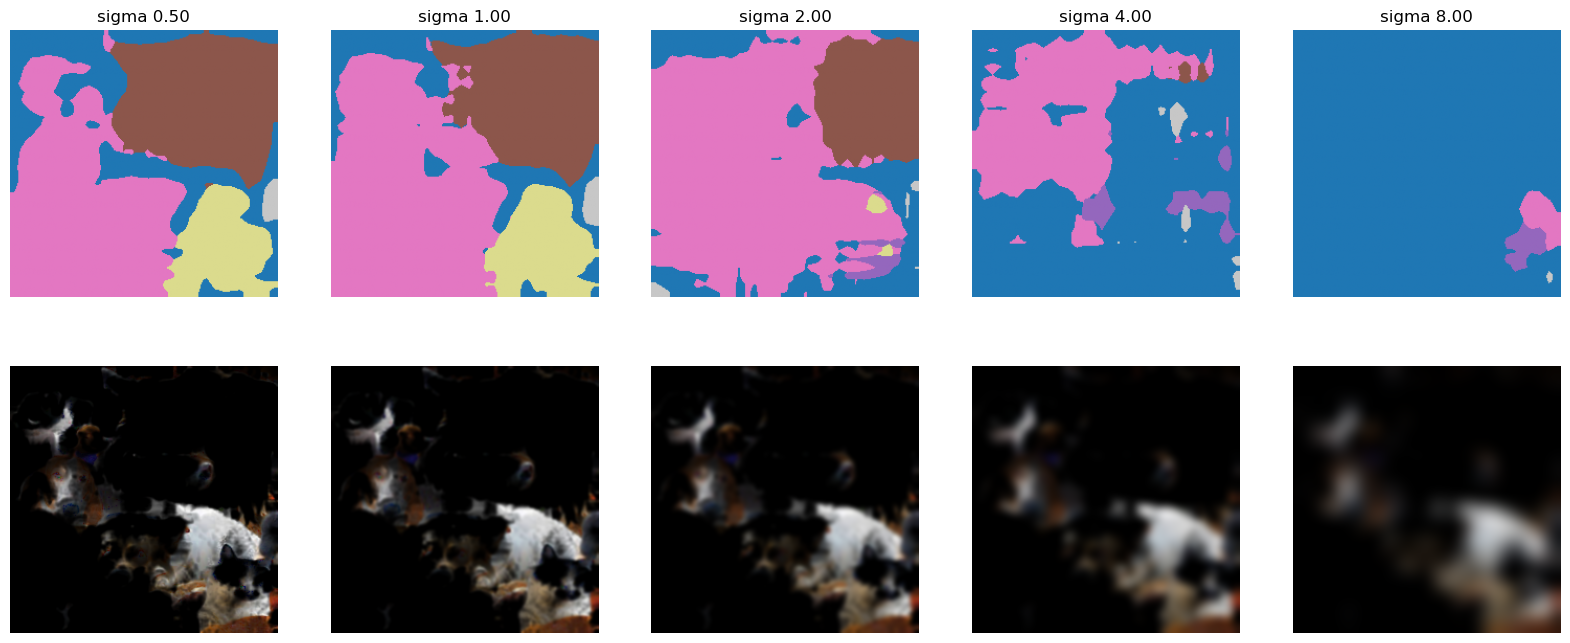

In [11]:
plt.figure(figsize=(20, 8))
sigma = 0.5
for i in range(5):
    input = torch.tensor(simplification).permute(2, 0, 1).to(device="cuda")
    k = 2 * np.floor(2 * sigma) + 1
    gaussian = GaussianBlur(k, sigma)
    input = gaussian(input)
    normalized_img = F.normalize(input, mean=(
        0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
    output = model(normalized_img.unsqueeze(0))['out']
    plt.subplot(2, 5, i + 1)
    plt.imshow(output.argmax(1).cpu().numpy().squeeze(),
               vmin=0, vmax=20, cmap="tab20")
    plt.title(f"sigma {(sigma):.2f}")
    plt.axis("off")
    plt.subplot(2, 5, i + 1 + 5)
    plt.imshow(input.permute(1, 2, 0).cpu().numpy())
    plt.axis("off")
    sigma = sigma * 2

/tmp/ipykernel_5075/3441089346.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  input = torch.tensor(transform).to(device="cuda")


torch.Size([3, 280, 280])
torch.Size([3, 280, 280])
torch.Size([3, 280, 280])
torch.Size([3, 280, 280])
torch.Size([3, 280, 280])
torch.Size([3, 280, 280])
torch.Size([3, 280, 280])


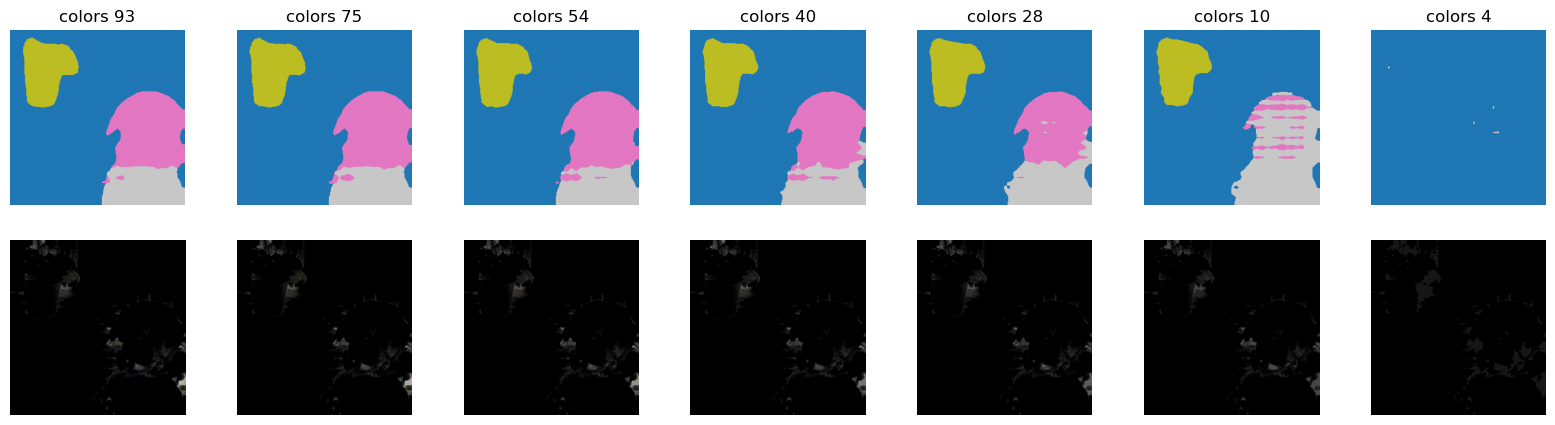

In [72]:
from torchvision.transforms.functional import to_pil_image
import torchvision.transforms as transforms
plt.figure(figsize=(20, 5))
colors = 256
n = 7
for i in range(n):
    im_q = to_pil_image(simplification)
    # for org image:
    # im_q = to_pil_image(simplification.permute(2, 0, 1))
    simplified_image = im_q.quantize(colors=colors)
    simplified_image = simplified_image.convert("RGB")
    transform = transforms.Compose([transforms.ToTensor()])
    transform = transform(simplified_image)
    input = torch.tensor(transform).to(device="cuda")
    print(input.shape)

    normalized_img = F.normalize(input, mean=(
        0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
    output = model(normalized_img.unsqueeze(0))['out']
    plt.subplot(2, n, i + 1)
    plt.imshow(output.argmax(1).cpu().numpy().squeeze(),
               vmin=0, vmax=20, cmap="tab20")
    plt.axis("off")
    plt.title(f"colors {len(torch.unique(input))}")
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(input.permute(1, 2, 0).cpu().numpy())
    plt.axis("off")
    colors = colors // 2